<a href="https://colab.research.google.com/github/onurhayta/group59_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1 — EDA and Baselines
**CENG313 Introduction to Data Science — GROUP59_CENG313**

Sadık Onur Hayta (23118080046)

Competition: [Hull Tactical – Market Prediction](https://www.kaggle.com/competitions/hull-tactical-market-prediction)

## 0. Setup

In [42]:
import os, sys

REPO_URL = "https://github.com/onurhayta/group59_CENG313.git"
REPO_DIR = "/content/group59_CENG313"

if "google.colab" in sys.modules:
    os.chdir("/content")
    if not os.path.exists(REPO_DIR):
        !git clone {REPO_URL} {REPO_DIR}
    else:
        !git -C {REPO_DIR} pull
    os.chdir(REPO_DIR)
sys.path.insert(0, os.getcwd())
print(os.getcwd(), os.listdir("src"))

remote: Enumerating objects: 5, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 3 (delta 2), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (3/3), 141.29 KiB | 408.00 KiB/s, done.
From https://github.com/onurhayta/group59_CENG313
   92c739b..a6078b4  main       -> origin/main
Updating 92c739b..a6078b4
Fast-forward
 assignment1_eda_baseline.ipynb | 768 ++++++++++++++++++++++++++++++++++++++---
 1 file changed, 718 insertions(+), 50 deletions(-)
/content/group59_CENG313 ['models.py', 'data.py', '__init__.py', '__pycache__', 'utils.py']


In [43]:
!pip install -q -U "kagglehub>=0.4.1"

import kagglehub

if "google.colab" in sys.modules:
    from google.colab import userdata
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

DATA_PATH = kagglehub.competition_download("hull-tactical-market-prediction")
print(DATA_PATH, os.listdir(DATA_PATH))

/root/.cache/kagglehub/competitions/hull-tactical-market-prediction ['test.csv', 'kaggle_evaluation', 'train.csv']


In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data, models, utils

train = data.load_train(DATA_PATH)
print(train.shape)
train.head()

(9048, 98)


,date_id,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,V3,V4,V5,V6,V7,V8,V9,forward_returns,risk_free_rate,market_forward_excess_returns
0,0,0,0,0,1,1,0,0,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.002421,0.000301,-0.003038
1,1,0,0,0,1,1,0,0,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.008495,0.000303,-0.009114
2,2,0,0,0,1,0,0,0,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.009624,0.000301,-0.010243
3,3,0,0,0,1,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.004662,0.000299,0.004046
4,4,0,0,0,1,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.011686,0.000299,-0.012301


## 1. Data overview

In [45]:
groups = data.group_features(train)
print("Rows:", len(train), "| date_id range:", train.date_id.min(), "-", train.date_id.max())

pd.DataFrame({
    "group": list(groups),
    "description": [data.FEATURE_GROUPS[g] for g in groups],
    "n_features": [len(cols) for cols in groups.values()],
})

Rows: 9048 | date_id range: 0 - 9047


,group,description,n_features
0,M,Market dynamics / technical,18
1,E,Macro-economic,20
2,I,Interest rates,9
3,P,Price / valuation,13
4,V,Volatility,13
5,S,Sentiment,12
6,D,Binary / dummy,9


The training set contains **9,048 trading days** (`date_id` 0–9047, roughly 36 years) and **94 anonymised features** in 7 groups. The `MOM*` group mentioned in some descriptions of the competition is not present in this version of the data. Dates are anonymised, so `date_id` only gives the order of the days.

In [46]:
train[data.TARGET_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
forward_returns,9048.0,0.000470,0.010535,-0.039754,-0.004321,0.000661,0.005891,0.040661
risk_free_rate,9048.0,0.000107,0.000088,-0.000004,0.000008,0.000099,0.000193,0.000317
market_forward_excess_returns,9048.0,0.000052,0.010552,-0.040582,-0.004751,0.000257,0.005469,0.040551


- `forward_returns` has a daily mean of 0.047% and a standard deviation of 1.05%, i.e. roughly 12% annual return and 17% annual volatility, which is realistic for the S&P 500.
- The minimum and maximum are almost symmetric at about ±4%. Real market crashes contain larger daily moves, so the target appears to be **clipped (winsorised)**.
- `market_forward_excess_returns` has a mean close to zero (0.005%), much smaller than `forward_returns − risk_free_rate` (≈0.036%). It is therefore not a simple excess return over the risk-free rate; it appears to be demeaned with a rolling long-term average. This is the target our models predict.
- The daily signal is tiny compared with the noise (mean ≈ 0.05 × std), which already suggests that predicting daily returns will be hard.

## 2. Exploratory data analysis
### 2.1 Missing values

In [47]:
miss = data.missing_summary(train)
miss.groupby("group").agg(
    n_features=("feature", "count"),
    mean_missing_ratio=("missing_ratio", "mean"),
    first_available=("first_valid_date_id", "min"),
    last_to_start=("first_valid_date_id", "max"),
).sort_values("mean_missing_ratio")

,n_features,mean_missing_ratio,first_available,last_to_start
group,,,,
D,9,0.000000,0,0
I,9,0.111185,1006,1006
P,13,0.126573,1006,1638
E,20,0.151807,1006,6969
V,13,0.196984,1006,6049
S,12,0.201131,1006,5733
M,18,0.253303,1006,5547


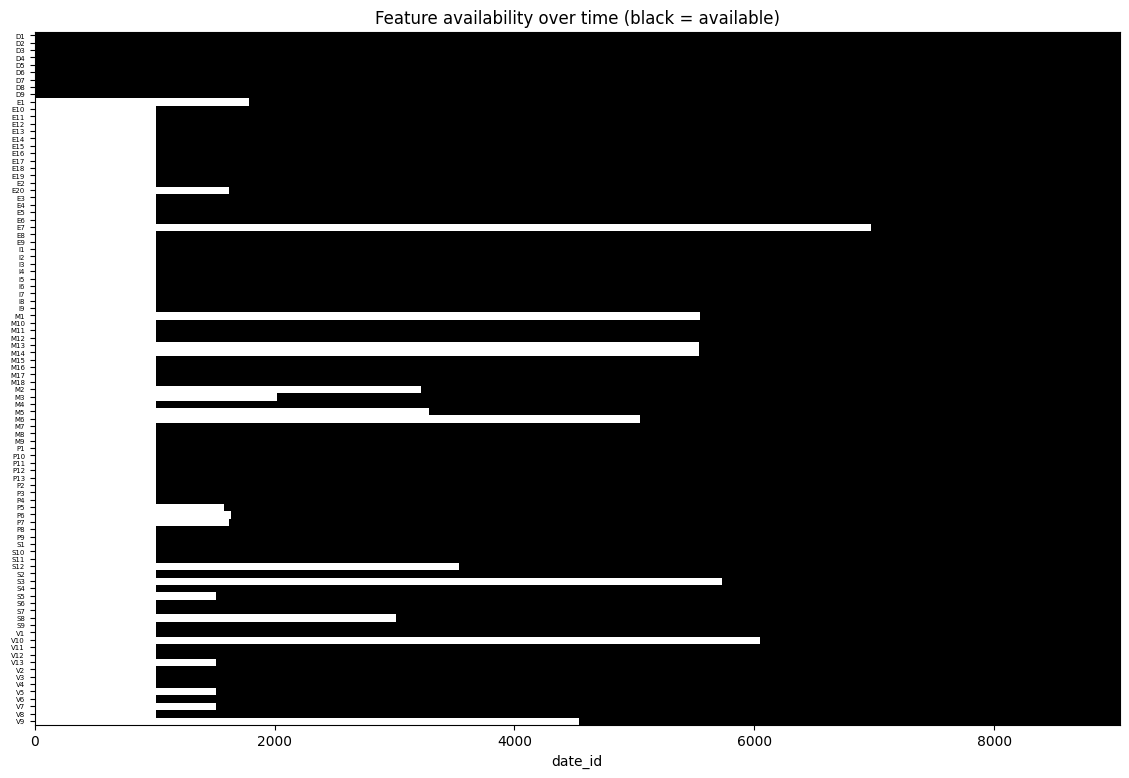

In [48]:
feats = data.get_feature_columns(train)

fig, ax = plt.subplots(figsize=(14, 9))
ax.imshow(train[feats].notna().T, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_yticks(range(len(feats)))
ax.set_yticklabels(feats, fontsize=5)
ax.set_xlabel("date_id")
ax.set_title("Feature availability over time (black = available)")
plt.show()

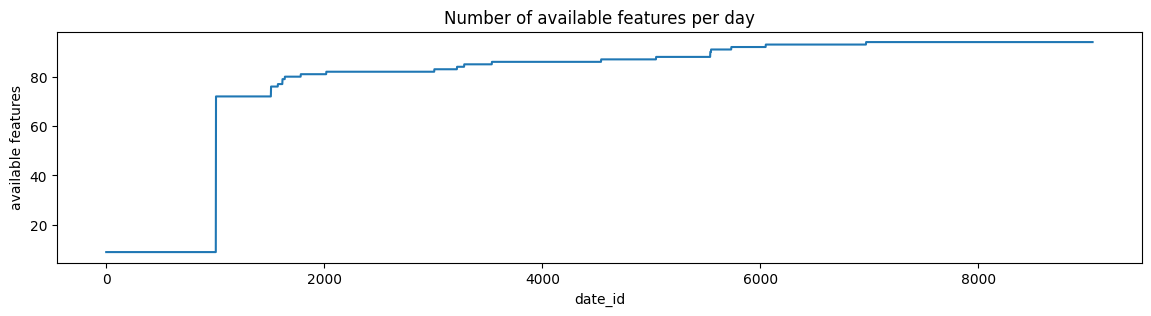

In [49]:
fig, ax = plt.subplots(figsize=(14, 3))
train[feats].notna().sum(axis=1).plot(ax=ax)
ax.set_xlabel("date_id")
ax.set_ylabel("available features")
ax.set_title("Number of available features per day")
plt.show()

**Findings:**
- For the **first 1,006 days only the 9 binary `D*` features are available**; all other groups are completely missing.
- At `date_id` 1006 about 72 features become available at once, and the number then grows step by step to all 94.
- Some features start very late: e.g. `E7` (~day 6969), `V10` (~6049), `S3` (~5733), `M1`/`M13` (~5547), so they exist only for the most recent part of the data.
- Missingness is structural (features start at a given date and stay available), not random gaps.

**Implications for modelling:**
- The first 1,006 rows carry almost no information and will be excluded from training.
- Linear models need imputation (median imputation in our Ridge baseline). LightGBM can handle missing values natively.
- Features that start late have little training history, so their relationships with the target are estimated from fewer observations.

### 2.2 Target distribution

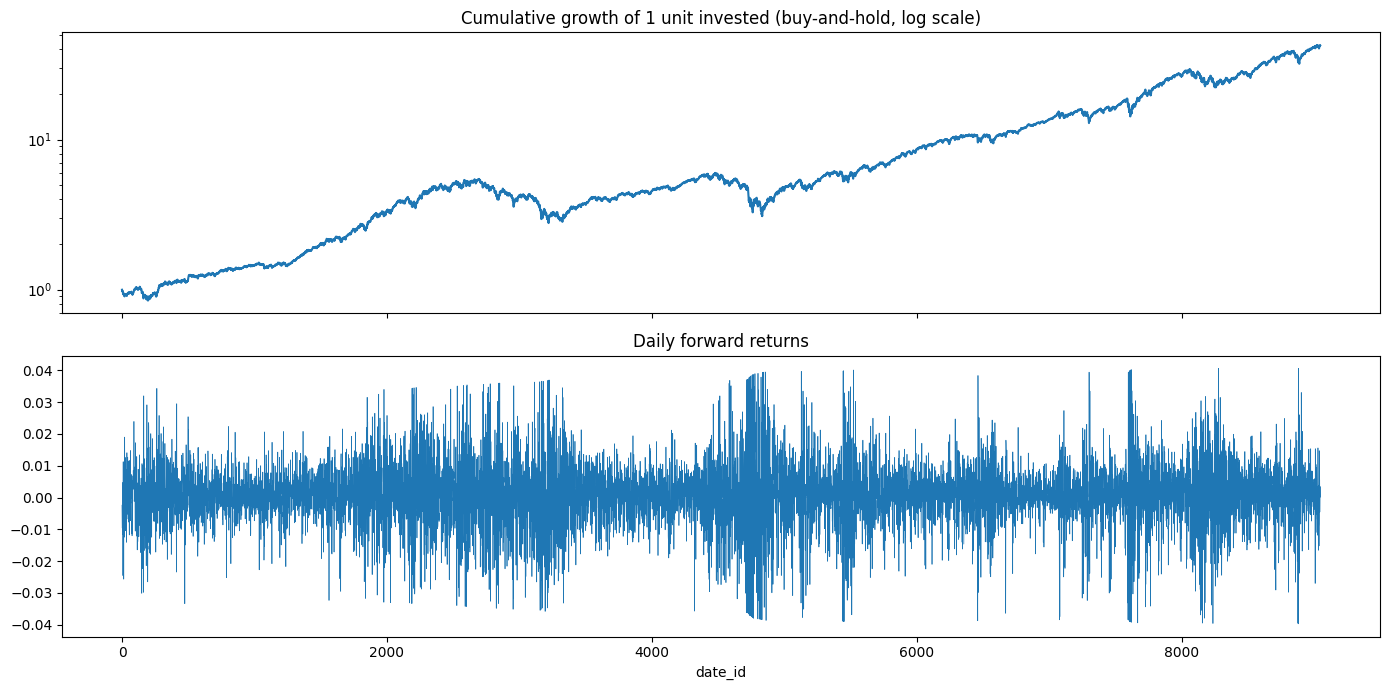

In [50]:
fwd = train["forward_returns"]

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
(1 + fwd).cumprod().plot(ax=axes[0], logy=True)
axes[0].set_title("Cumulative growth of 1 unit invested (buy-and-hold, log scale)")
fwd.plot(ax=axes[1], lw=0.5)
axes[1].set_title("Daily forward returns")
axes[1].set_xlabel("date_id")
plt.tight_layout()
plt.show()

- Buy-and-hold grows 1 unit to roughly 45 units over the sample, but with several large drawdowns (around `date_id` ~3300, ~4900 and ~7600). Dates are anonymised, but these are consistent with the 2000–2002, 2008 and 2020 market crises.
- The daily returns show clear **volatility clustering**: calm periods with small moves alternate with turbulent periods with large moves. In the most turbulent period many returns hit the ±4% bounds, which again shows that the target is clipped.

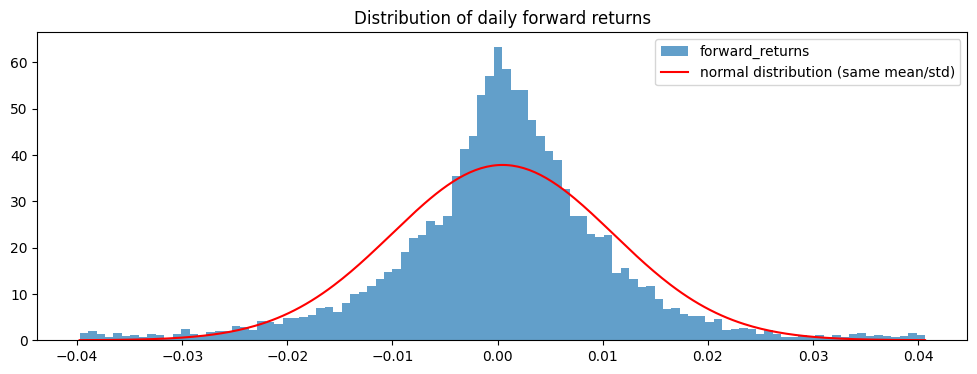

Skewness: -0.178
Excess kurtosis: 2.199
Share of positive days: 0.540


In [51]:
from scipy import stats

fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(fwd, bins=100, density=True, alpha=0.7, label="forward_returns")
x = np.linspace(fwd.min(), fwd.max(), 300)
ax.plot(x, stats.norm.pdf(x, fwd.mean(), fwd.std()), "r", label="normal distribution (same mean/std)")
ax.set_title("Distribution of daily forward returns")
ax.legend()
plt.show()

print(f"Skewness: {fwd.skew():.3f}")
print(f"Excess kurtosis: {fwd.kurt():.3f}")
print(f"Share of positive days: {(fwd > 0).mean():.3f}")

- The distribution is **more peaked and has fatter tails** than a normal distribution with the same mean and standard deviation (excess kurtosis ≈ 2.2), so extreme days are more frequent than a normal model would predict.
- It is slightly **negatively skewed** (≈ −0.18): large down moves are somewhat more common than large up moves.
- 54% of days are positive. Always being in the market is therefore right slightly more often than not, which is why buy-and-hold is a strong baseline.
- The small spikes at ±0.04 are produced by the clipping of the target.

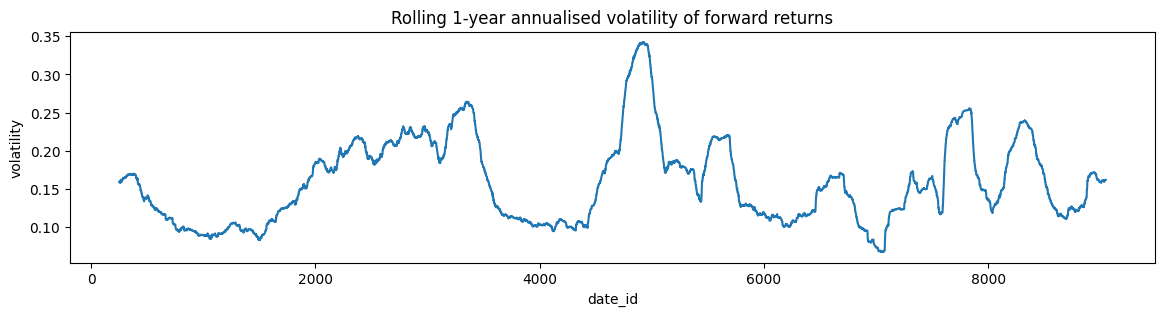

In [52]:
rolling_vol = fwd.rolling(252).std() * np.sqrt(252)

fig, ax = plt.subplots(figsize=(14, 3))
rolling_vol.plot(ax=ax)
ax.set_title("Rolling 1-year annualised volatility of forward returns")
ax.set_xlabel("date_id")
ax.set_ylabel("volatility")
plt.show()

- Annualised volatility varies between roughly **9% and 34%**, i.e. by a factor of about 3.5 between calm and turbulent regimes.
- Because the competition penalises strategies whose volatility is above 1.2× the market's, the same allocation carries very different risk in different regimes. This suggests sizing positions with respect to current volatility.

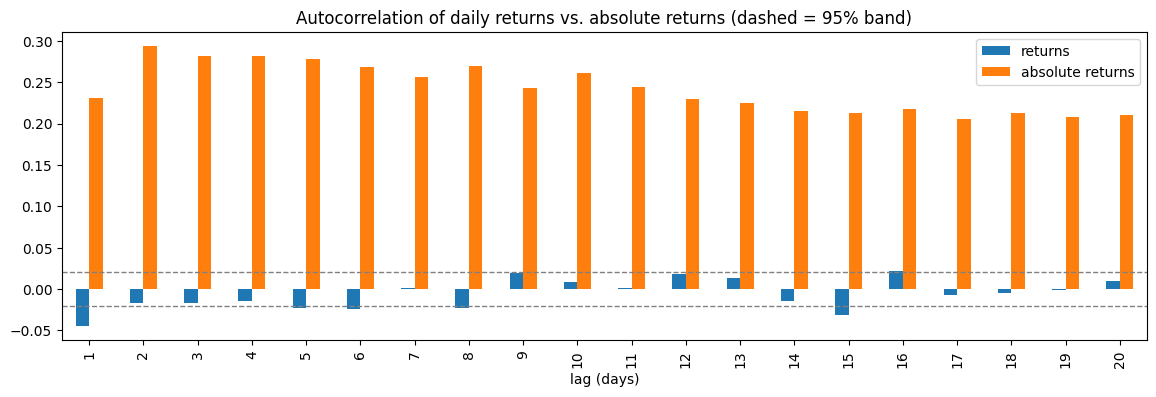

In [53]:
lags = range(1, 21)
acf = pd.DataFrame({
    "returns": [fwd.autocorr(lag) for lag in lags],
    "absolute returns": [fwd.abs().autocorr(lag) for lag in lags],
}, index=lags)

ax = acf.plot.bar(figsize=(14, 4))
band = 1.96 / np.sqrt(len(fwd))
ax.axhline(band, color="grey", ls="--", lw=1)
ax.axhline(-band, color="grey", ls="--", lw=1)
ax.set_xlabel("lag (days)")
ax.set_title("Autocorrelation of daily returns vs. absolute returns (dashed = 95% band)")
plt.show()

- The autocorrelation of **returns** is close to zero at all lags (only lag 1 is slightly negative and marginally outside the 95% band). Past returns carry almost no information about the *direction* of the next day's return.
- The autocorrelation of **absolute returns** is strongly positive (0.2–0.3) and decays slowly over 20 days. The *size* of moves, i.e. volatility, is persistent and therefore predictable.
- **Implication:** predicting the next day's return is expected to be very hard, while predicting volatility is feasible. Combining a return forecast with a volatility forecast is a promising direction for Assignment 2.

### 2.3 Feature–target relationships
Only rows from `date_id` 1006 onwards are used, because earlier rows contain only the `D*` features. The target is `market_forward_excess_returns`. Spearman (rank) correlation is reported in addition to Pearson because it is robust to outliers and fat tails.

In [54]:
TARGET = "market_forward_excess_returns"
df = train[train.date_id >= 1006]

corr = pd.DataFrame({
    "group": [data.feature_group(f) for f in feats],
    "pearson": [df[f].corr(df[TARGET]) for f in feats],
    "spearman": [df[f].corr(df[TARGET], method="spearman") for f in feats],
    "n_obs": [df[f].notna().sum() for f in feats],
}, index=feats)
corr["abs_spearman"] = corr["spearman"].abs()

corr.sort_values("abs_spearman", ascending=False).head(15)

,group,pearson,spearman,n_obs,abs_spearman
M1,M,0.046433,0.053579,3501,0.053579
M4,M,-0.066632,-0.053160,8042,0.053160
V13,V,0.062378,0.046389,7537,0.046389
S2,S,-0.038493,-0.045605,8042,0.045605
V10,V,0.032859,0.044235,2999,0.044235
P5,P,-0.023136,-0.041517,7474,0.041517
S5,S,0.040009,0.039176,7537,0.039176
V7,V,0.031623,0.036979,7537,0.036979
E19,E,0.023862,0.035651,8042,0.035651
V9,V,0.016877,0.033138,4509,0.033138


- The strongest single feature (`M1`) has a Spearman correlation of only **0.054** with the target; all correlations are below 0.06 in absolute value. No feature is individually strongly predictive.
- `M1` and `V10` start late in the sample (≈3,500 and ≈3,000 observations), so their correlations are estimated from the most recent period only and are less reliable.
- `D1` and `D2` have identical correlations, which suggests they are duplicates or nearly identical features.

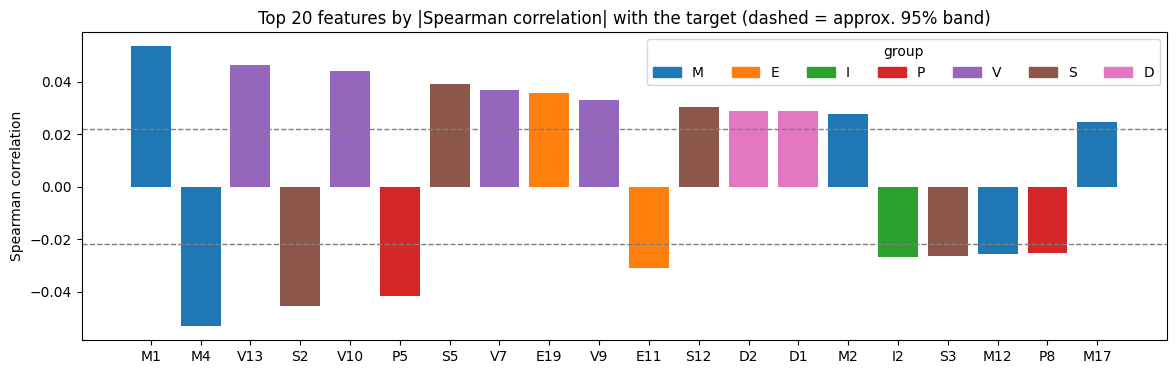

In [55]:
top = corr.sort_values("abs_spearman", ascending=False).head(20)
group_colors = {g: f"C{i}" for i, g in enumerate(groups)}

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(top.index, top["spearman"], color=top["group"].map(group_colors))
band = 1.96 / np.sqrt(len(df))
ax.axhline(band, color="grey", ls="--", lw=1)
ax.axhline(-band, color="grey", ls="--", lw=1)
ax.set_title("Top 20 features by |Spearman correlation| with the target (dashed = approx. 95% band)")
ax.set_ylabel("Spearman correlation")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in group_colors.values()]
ax.legend(handles, group_colors.keys(), title="group", ncol=7)
plt.show()

- Around 20 features lie outside the approximate 95% band (±0.022). However, with 94 features tested, about 5 would exceed the band by chance alone, so some of these may be spurious.
- Both positive and negative relationships appear, and the strongest features come from different groups (M, V, S, P, E).

In [56]:
corr.groupby("group")["abs_spearman"].agg(["mean", "max"]).sort_values("max", ascending=False)

,mean,max
group,,
M,0.018273,0.053579
V,0.017356,0.046389
S,0.017711,0.045605
P,0.010882,0.041517
E,0.010731,0.035651
D,0.018644,0.029084
I,0.006979,0.026655


- The **M** (market dynamics), **V** (volatility) and **S** (sentiment) groups contain the strongest individual features; **I** (interest rates) is the weakest group.
- The differences between groups are small, so no group can be discarded on this basis alone.

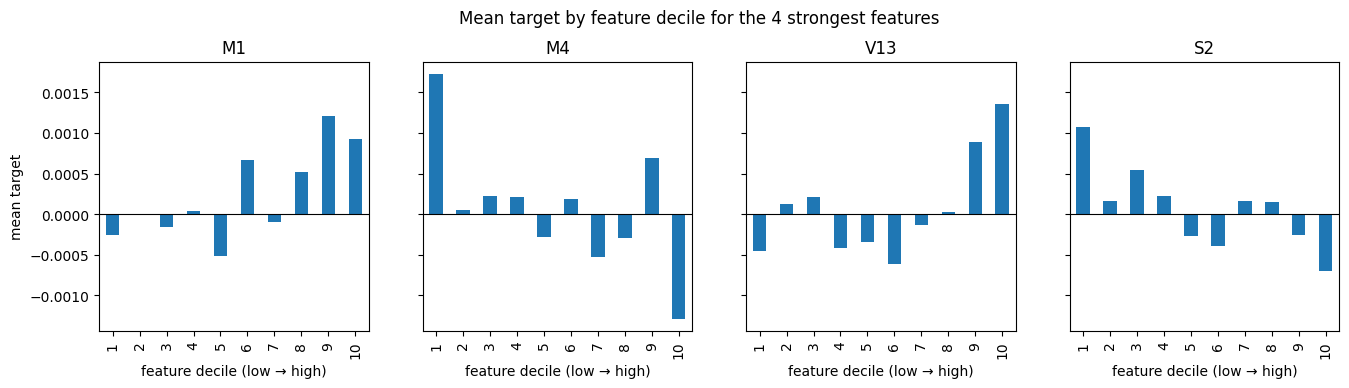

In [57]:
top4 = corr.sort_values("abs_spearman", ascending=False).index[:4]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, f in zip(axes, top4):
    deciles = pd.qcut(df[f].rank(method="first"), 10, labels=range(1, 11))
    df.groupby(deciles, observed=True)[TARGET].mean().plot.bar(ax=ax)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f)
    ax.set_xlabel("feature decile (low → high)")
axes[0].set_ylabel("mean target")
plt.suptitle("Mean target by feature decile for the 4 strongest features", y=1.03)
plt.show()

- The relationships are **noisy and not monotonic**: the mean target does not increase or decrease smoothly across deciles.
- Much of the signal is concentrated in the **extreme deciles** (e.g. the top decile of `M4` is strongly negative, the top two deciles of `V13` are positive). Such non-linear, tail-driven effects are better captured by tree-based models such as LightGBM than by linear models.

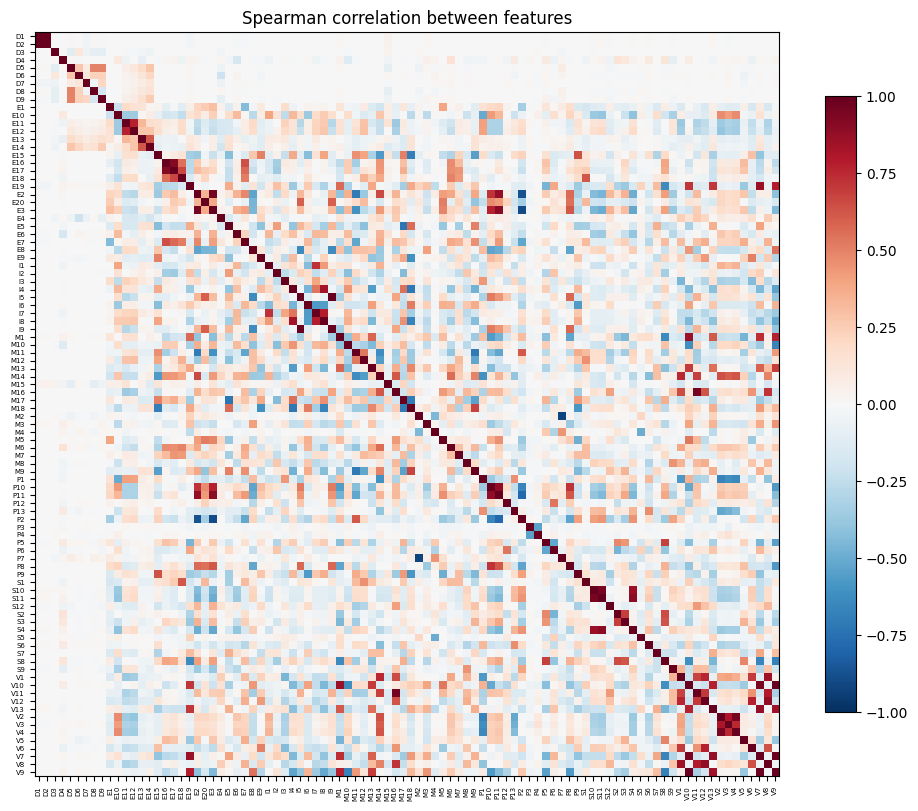

Feature pairs with |correlation| > 0.9: 12


In [58]:
feat_corr = df[feats].corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(feat_corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(feats)))
ax.set_xticklabels(feats, fontsize=5, rotation=90)
ax.set_yticks(range(len(feats)))
ax.set_yticklabels(feats, fontsize=5)
ax.set_title("Spearman correlation between features")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.show()

high_pairs = (feat_corr.abs() > 0.9).sum().sum() - len(feats)
print("Feature pairs with |correlation| > 0.9:", high_pairs // 2)

- Several **blocks of highly correlated features** exist, mostly within the same group (e.g. within `V*`, parts of `E*`, and `P10`/`P11`). N feature pairs have an absolute correlation above 0.9.
- This multicollinearity means many features carry overlapping information. Regularisation (Ridge) or tree models are preferred over plain linear regression, and feature selection may help in Assignment 2.

### 2.4 Stability over time
The rows from `date_id` 1006 onwards are split into 8 consecutive periods of about 1,000 days. For the 10 strongest features from Section 2.3, the Spearman correlation with the target is computed separately in each period. With ~1,000 observations per period, correlations within about ±0.06 are not statistically distinguishable from zero.

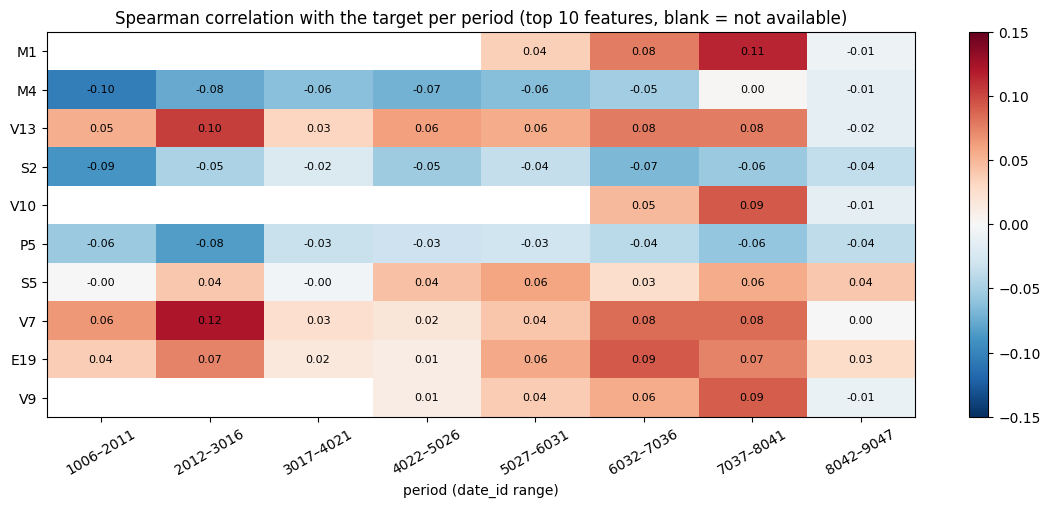

In [59]:
n_blocks = 8
df_blocks = df.assign(block=pd.qcut(df.date_id, n_blocks, labels=range(1, n_blocks + 1)))
top10 = corr.sort_values("abs_spearman", ascending=False).index[:10]

block_groups = list(df_blocks.groupby("block", observed=True))
block_corr = pd.DataFrame({
    b: [g[f].corr(g[TARGET], method="spearman") for f in top10]
    for b, g in block_groups
}, index=top10)
block_labels = [f"{g.date_id.min()}–{g.date_id.max()}" for _, g in block_groups]

fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(block_corr, cmap="RdBu_r", vmin=-0.15, vmax=0.15, aspect="auto")
ax.set_xticks(range(n_blocks))
ax.set_xticklabels(block_labels, rotation=30)
ax.set_yticks(range(len(top10)))
ax.set_yticklabels(top10)
for i in range(len(top10)):
    for j in range(n_blocks):
        v = block_corr.iloc[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)
ax.set_xlabel("period (date_id range)")
ax.set_title("Spearman correlation with the target per period (top 10 features, blank = not available)")
plt.colorbar(im, ax=ax)
plt.show()

- The **strength** of the relationships varies considerably between periods (from about 0.00 to 0.12 in absolute value), even when the direction stays the same.
- In the **most recent period (8042–9047) almost all signals disappear**: `M1`, `M4`, `V13`, `V10`, `V9` and `V7` are all between −0.02 and 0.00. This is the period closest to the test data, so it is an important warning sign.
- The late-starting features (`M1`, `V10`, `V9`) look strong in 6032–8041 but vanish afterwards, so their overall correlation is largely driven by a single period.
- The negative relationship of `M4` weakens over time, from −0.10 in the first period to about 0.00 at the end.

In [60]:
overall = corr.loc[top10, "spearman"]
n_available = block_corr.notna().sum(axis=1)
same_sign = np.sign(block_corr).eq(np.sign(overall), axis=0).sum(axis=1)

pd.DataFrame({
    "overall_spearman": overall,
    "periods_available": n_available,
    "periods_same_sign": same_sign,
    "share_same_sign": same_sign / n_available,
})

,overall_spearman,periods_available,periods_same_sign,share_same_sign
M1,0.053579,4,3,0.750000
M4,-0.053160,8,7,0.875000
V13,0.046389,8,7,0.875000
S2,-0.045605,8,8,1.000000
V10,0.044235,3,2,0.666667
P5,-0.041517,8,8,1.000000
S5,0.039176,8,6,0.750000
V7,0.036979,8,8,1.000000
E19,0.035651,8,8,1.000000
V9,0.033138,5,4,0.800000


- The **direction** of the relationship is fairly stable: `S2`, `P5`, `V7` and `E19` have the same sign in all 8 periods, and `M4` and `V13` in 7 of 8.
- Features with only a few periods of history (`M1`: 4, `V10`: 3, `V9`: 5) are less consistent, and their stability cannot be judged reliably.

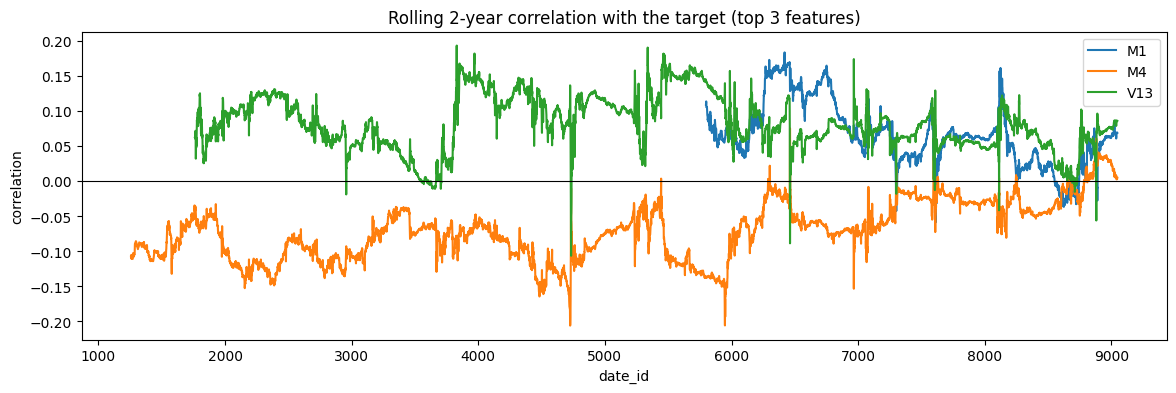

In [61]:
s = df.set_index("date_id")

fig, ax = plt.subplots(figsize=(14, 4))
for f in top10[:3]:
    s[f].rolling(504, min_periods=252).corr(s[TARGET]).plot(ax=ax, label=f)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("date_id")
ax.set_ylabel("correlation")
ax.set_title("Rolling 2-year correlation with the target (top 3 features)")
ax.legend()
plt.show()

- The rolling correlations fluctuate strongly, with sudden jumps around turbulent periods, and drift towards zero at the end of the sample.

**Implications for modelling:**
- The relationships are **non-stationary**: a signal that worked in the past can weaken or disappear later. Models must be evaluated with **time-ordered walk-forward validation**, never with random splits.
- Results on a single period can be misleading, so performance should be reported across several validation folds.
- Strong regularisation is needed to avoid fitting period-specific noise. Giving more weight to recent data, or training on a rolling window, are options to test in Assignment 2.
- Out-of-sample improvements over buy-and-hold are expected to be small.